# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023.

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**

In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately.
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
os.makedirs('images', exist_ok=True)  # key visuals are saved here for the README

## Exploratory Data Analysis
- Load in the cleaned data

In [2]:
df = pd.read_csv('cleaned_aviation_data.csv', parse_dates=['Event.Date'])

print(df.shape)
df[['Make', 'Model', 'Make.Model', 'Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed']].describe(include='all').T

(59228, 27)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Make,59228,50,CESSNA,25441,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,59228,4207,152,2211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make.Model,59228,4424,CESSNA 152,2211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total.Passengers,59228.0,NaN,NaN,NaN,5.010519,24.382261,1.0,1.0,2.0,2.0,699.0
Fatal.Serious.Fraction,59228.0,NaN,NaN,NaN,0.2705,0.429174,0.0,0.0,0.0,0.666667,1.0
Destroyed,59228.0,NaN,NaN,NaN,0.21034,0.407553,0.0,0.0,0.0,0.0,1.0


In [3]:
print('Events per year (first and last years):')
print(df['Event.Date'].dt.year.value_counts().sort_index().iloc[[0, 1, -2, -1]])
print()
print('Overall mean fatal/serious fraction:', round(df['Fatal.Serious.Fraction'].mean(), 3))
print('Overall destroyed rate:', round(df['Destroyed'].mean(), 3))

Events per year (first and last years):
Event.Date
1983    2742
1984    2688
2021     842
2022     842
Name: count, dtype: int64

Overall mean fatal/serious fraction: 0.271
Overall destroyed rate: 0.21


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types.

**Approach.** An airplane *type* (`Make.Model`) is classified as **Large** if the 95th percentile of the number of people on board across its recorded accidents is at least 20, otherwise **Small**. The 95th percentile is used instead of the maximum because a single mis-recorded or unusual event (for example a mid-air collision or a data entry error on a Piper PA-28-181) would push a four-seat plane into the large category. Cargo-heavy jets are still classified as large since most of their events involve far more than 20 people on board or have a high 95th percentile.

In [4]:
THRESHOLD = 20

p95_people = df.groupby('Make.Model')['Total.Passengers'].quantile(0.95)
df['Size'] = np.where(df['Make.Model'].map(p95_people) >= THRESHOLD, 'Large', 'Small')

small = df[df['Size'] == 'Small'].copy()
large = df[df['Size'] == 'Large'].copy()

print(df['Size'].value_counts())
print()
print('Large makes (events):')
print(large['Make'].value_counts())

Size
Small    57574
Large     1654
Name: count, dtype: int64

Large makes (events):
Make
BOEING               852
MCDONNELL DOUGLAS    181
AIRBUS               126
DOUGLAS              110
BEECH                 94
EMBRAER               78
BOMBARDIER            72
DE HAVILLAND          57
FAIRCHILD             39
LOCKHEED              32
AERO COMMANDER        10
GRUMMAN                1
CESSNA                 1
GULFSTREAM             1
Name: count, dtype: int64


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

**Sample size rule.** To keep the comparison statistically meaningful, only makes with at least 50 events (small planes) or at least 30 events (large planes, since there are fewer large-plane accidents) are ranked. The tables also include a 95% confidence interval on the mean so that differences smaller than the uncertainty are not over-interpreted.

Small makes ranked: 47 | Large makes ranked: 10


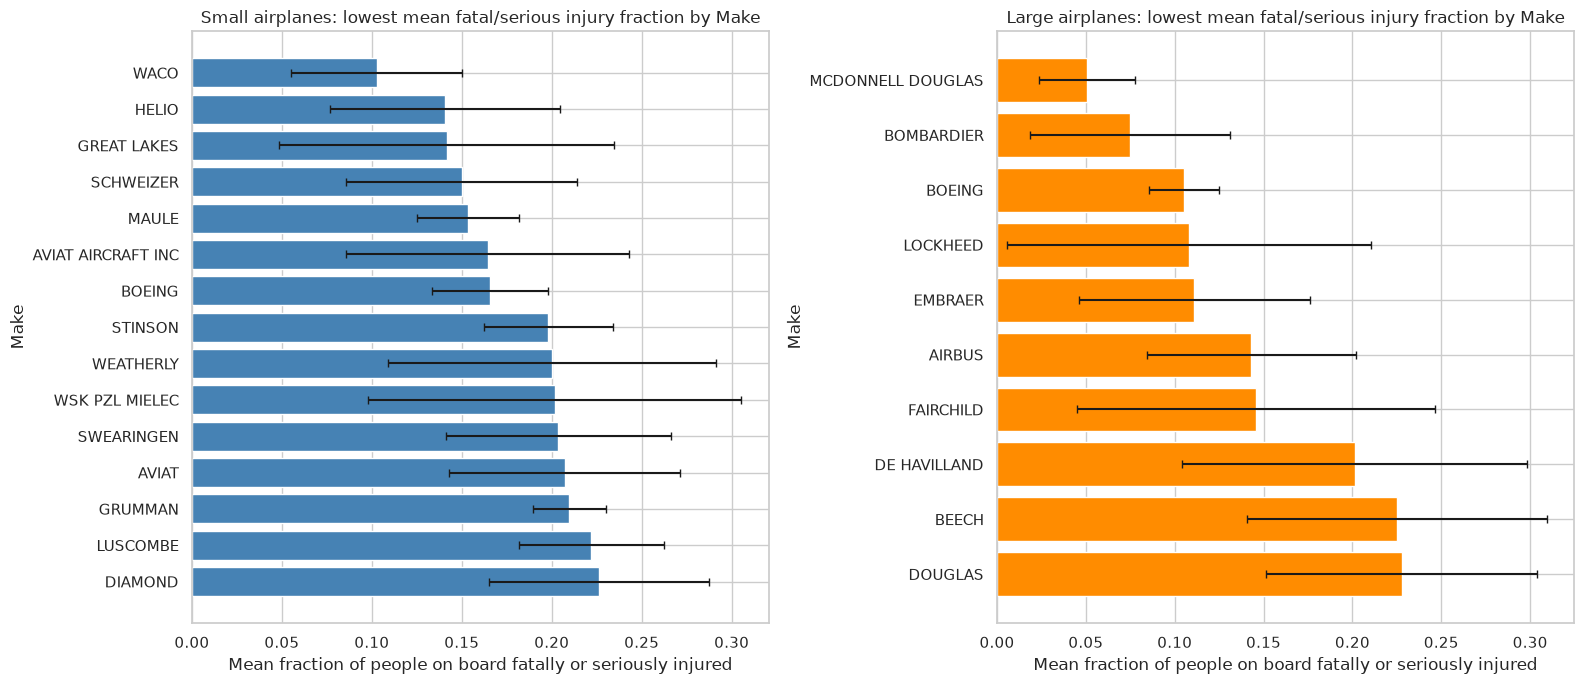

,n_events,mean_fatal_serious,destroyed_rate,ci95
Make,,,,
WACO,138,0.103,0.087,0.047
HELIO,105,0.141,0.124,0.064
GREAT LAKES,53,0.142,0.113,0.093
SCHWEIZER,120,0.150,0.225,0.064
MAULE,569,0.153,0.093,0.028
AVIAT AIRCRAFT INC,76,0.164,0.039,0.079
BOEING,452,0.166,0.126,0.032
STINSON,421,0.198,0.133,0.036
WEATHERLY,75,0.200,0.213,0.091


,n_events,mean_fatal_serious,destroyed_rate,ci95
Make,,,,
MCDONNELL DOUGLAS,181,0.051,0.088,0.027
BOMBARDIER,72,0.075,0.069,0.056
BOEING,852,0.105,0.112,0.020
LOCKHEED,32,0.108,0.156,0.102
EMBRAER,78,0.111,0.103,0.065
AIRBUS,126,0.143,0.151,0.059
FAIRCHILD,39,0.146,0.205,0.101
DE HAVILLAND,57,0.201,0.211,0.097
BEECH,94,0.225,0.191,0.084


In [5]:
MIN_EVENTS = {'Small': 50, 'Large': 30}

def make_summary(data, min_events):
    g = data.groupby('Make').agg(
        n_events=('Make', 'size'),
        mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
        sem=('Fatal.Serious.Fraction', 'sem'),
        destroyed_rate=('Destroyed', 'mean'),
    )
    g['ci95'] = 1.96 * g['sem']
    g = g[g['n_events'] >= min_events]
    return g.drop(columns='sem')

small_makes = make_summary(small, MIN_EVENTS['Small'])
large_makes = make_summary(large, MIN_EVENTS['Large'])

print('Small makes ranked:', len(small_makes), '| Large makes ranked:', len(large_makes))

small_lowest = small_makes.sort_values('mean_fatal_serious').head(15)
large_lowest = large_makes.sort_values('mean_fatal_serious').head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title, color in [(axes[0], small_lowest, 'Small airplanes', 'steelblue'),
                               (axes[1], large_lowest, 'Large airplanes', 'darkorange')]:
    ax.barh(data.index, data['mean_fatal_serious'], xerr=data['ci95'], color=color, capsize=3)
    ax.invert_yaxis()
    ax.set_title(f'{title}: lowest mean fatal/serious injury fraction by Make')
    ax.set_xlabel('Mean fraction of people on board fatally or seriously injured')
    ax.set_ylabel('Make')
plt.tight_layout()
plt.savefig('images/mean_injury_fraction_by_make.png', dpi=130)
plt.show()

display(small_lowest.round(3))
display(large_lowest.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

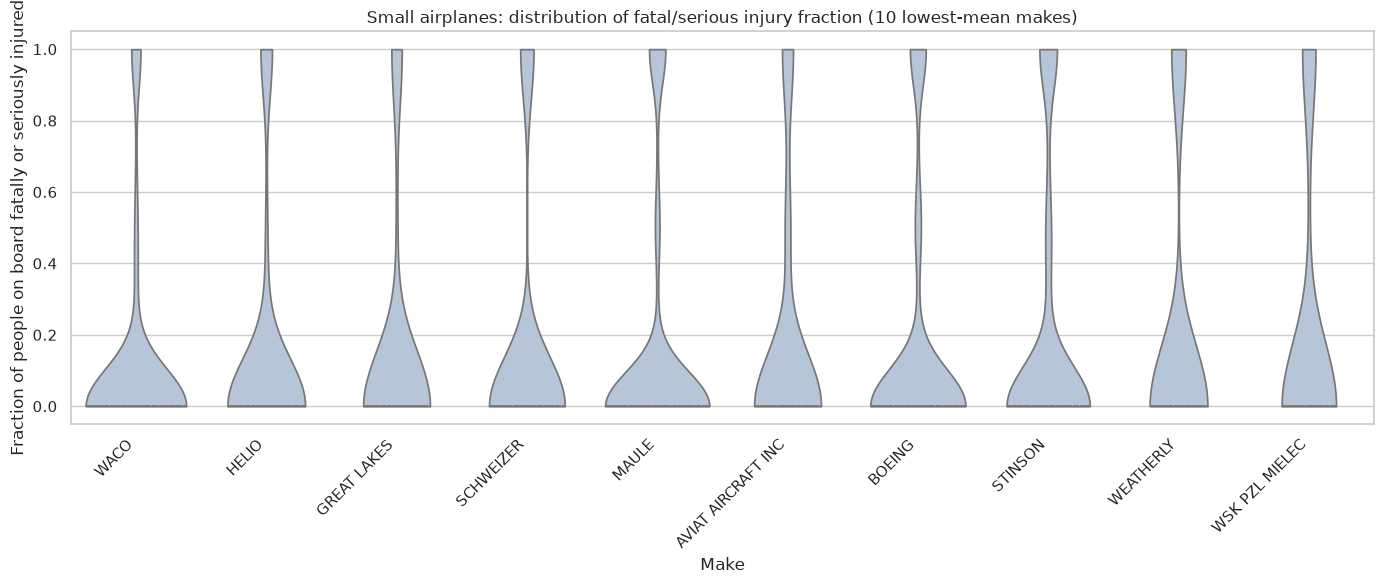

In [6]:
small_top10 = small_makes.sort_values('mean_fatal_serious').head(10).index

plt.figure(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(small_top10)], x='Make', y='Fatal.Serious.Fraction',
               order=small_top10, cut=0, inner='quartile', color='lightsteelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Small airplanes: distribution of fatal/serious injury fraction (10 lowest-mean makes)')
plt.xlabel('Make')
plt.ylabel('Fraction of people on board fatally or seriously injured')
plt.tight_layout()
plt.savefig('images/violin_small_makes.png', dpi=130)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

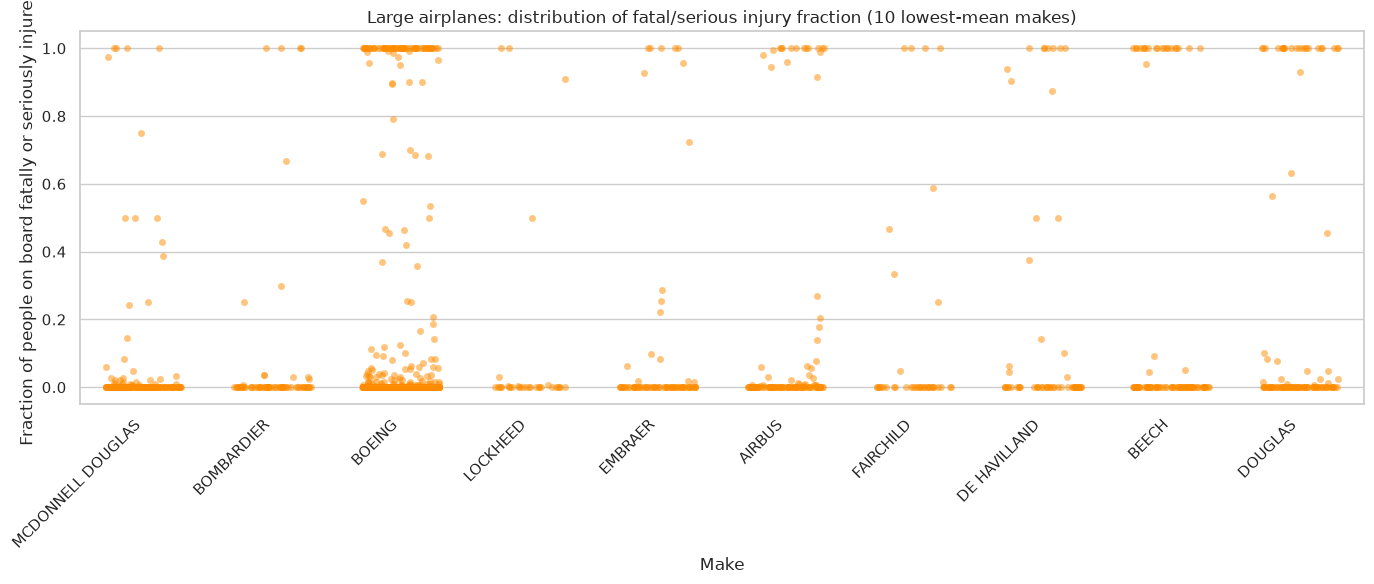

In [7]:
large_top10 = large_makes.sort_values('mean_fatal_serious').head(10).index

plt.figure(figsize=(14, 6))
sns.stripplot(data=large[large['Make'].isin(large_top10)], x='Make', y='Fatal.Serious.Fraction',
              order=large_top10, jitter=0.3, alpha=0.5, size=5, color='darkorange')
plt.xticks(rotation=45, ha='right')
plt.title('Large airplanes: distribution of fatal/serious injury fraction (10 lowest-mean makes)')
plt.xlabel('Make')
plt.ylabel('Fraction of people on board fatally or seriously injured')
plt.tight_layout()
plt.savefig('images/strip_large_makes.png', dpi=130)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.**

Sort your results and keep the lowest 15.

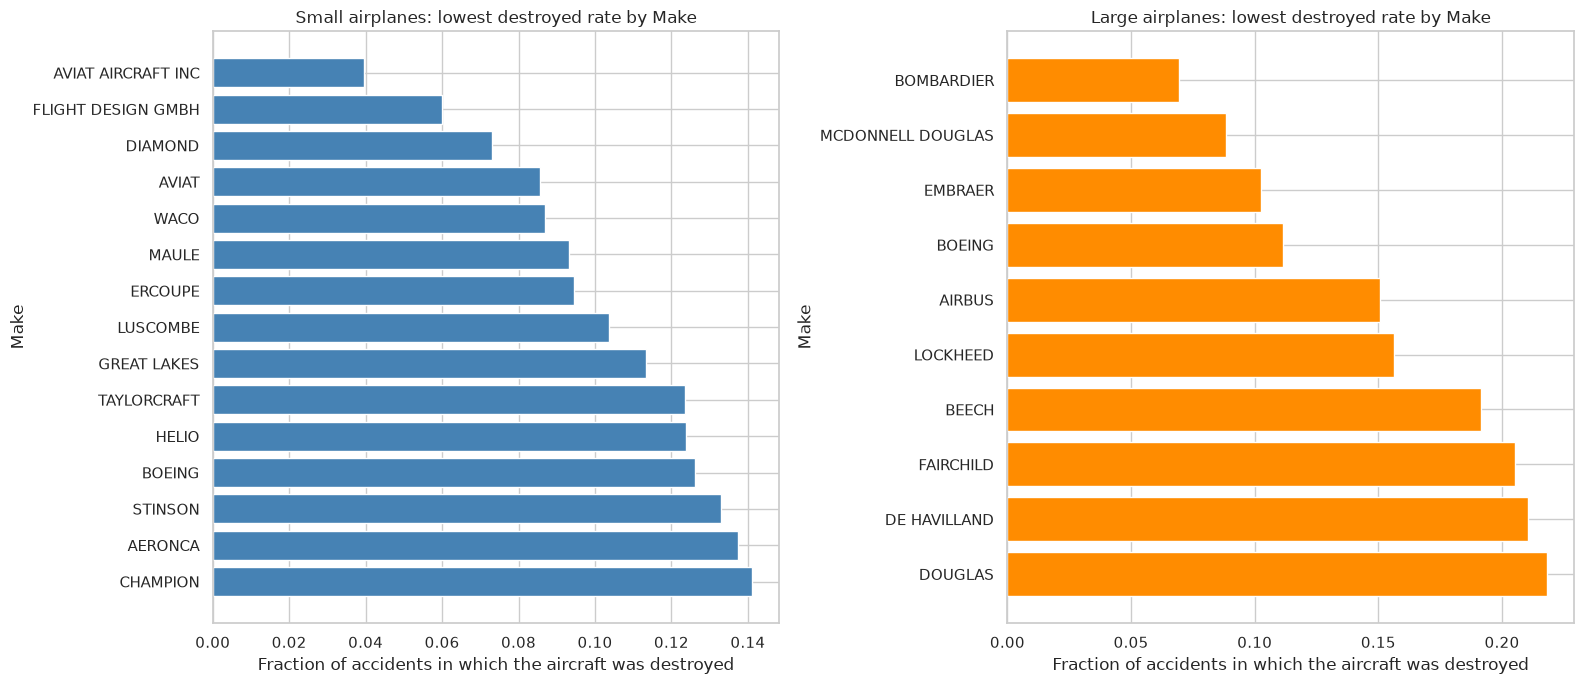

,n_events,destroyed_rate,mean_fatal_serious
Make,,,
AVIAT AIRCRAFT INC,76,0.039,0.164
FLIGHT DESIGN GMBH,50,0.060,0.370
DIAMOND,164,0.073,0.226
AVIAT,140,0.086,0.207
WACO,138,0.087,0.103
MAULE,569,0.093,0.153
ERCOUPE,74,0.095,0.340
LUSCOMBE,386,0.104,0.222
GREAT LAKES,53,0.113,0.142


,n_events,destroyed_rate,mean_fatal_serious
Make,,,
BOMBARDIER,72,0.069,0.075
MCDONNELL DOUGLAS,181,0.088,0.051
EMBRAER,78,0.103,0.111
BOEING,852,0.112,0.105
AIRBUS,126,0.151,0.143
LOCKHEED,32,0.156,0.108
BEECH,94,0.191,0.225
FAIRCHILD,39,0.205,0.146
DE HAVILLAND,57,0.211,0.201


In [8]:
small_destroyed = small_makes.sort_values('destroyed_rate').head(15)[['n_events', 'destroyed_rate', 'mean_fatal_serious']]
large_destroyed = large_makes.sort_values('destroyed_rate').head(15)[['n_events', 'destroyed_rate', 'mean_fatal_serious']]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(small_destroyed.index, small_destroyed['destroyed_rate'], color='steelblue')
axes[0].set_title('Small airplanes: lowest destroyed rate by Make')
axes[1].barh(large_destroyed.index, large_destroyed['destroyed_rate'], color='darkorange')
axes[1].set_title('Large airplanes: lowest destroyed rate by Make')
for ax in axes:
    ax.invert_yaxis()
    ax.set_xlabel('Fraction of accidents in which the aircraft was destroyed')
    ax.set_ylabel('Make')
plt.tight_layout()
plt.savefig('images/destroyed_rate_by_make.png', dpi=130)
plt.show()

display(small_destroyed.round(3))
display(large_destroyed.round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

**Overall picture.** Across all events the average fatal/serious injury fraction is about 0.27 for small planes and 0.12 for large planes, and the aircraft is destroyed in roughly 21% (small) and 13% (large) of accidents. The injury fraction is strongly bimodal: about 69% of small-plane and 77% of large-plane accidents have *no* fatal or serious injuries, so a make's mean is mostly driven by how often an accident is catastrophic. That is why the 95% confidence intervals (error bars) matter, and why only makes with enough events are ranked.

**Small airplanes.**
- Lowest mean injury fractions: Waco (0.103), Helio (0.141), Great Lakes (0.142), Schweizer (0.150) and **Maule (0.153)**. Waco, Helio, Great Lakes and Schweizer have wide intervals (50 to 140 events), so they cannot be statistically separated from several makes below them in the ranking.
- **Maule is the best-supported recommendation for small planes**: 569 events (interval of only +/-0.028), a low injury fraction (0.153) *and* a low destroyed rate (0.093). Aviat (0.039 / 0.086 destroyed) and Diamond (0.073 destroyed) have the lowest destruction rates, but Diamond's injury fraction (0.226) is middling.
- The mainstream high-volume makes sit higher: Cessna 0.241 (25,440 events), Piper 0.299, Beech 0.371 and Mooney 0.362. The lowest-risk makes are mostly slow, light utility, tail-wheel or vintage designs, so part of the difference is explained by the type of aircraft and flying rather than the manufacturer alone.
- The `BOEING` entry in the small list is not an airliner: it is made up of vintage Boeing-Stearman biplanes (Model 75 / PT-17), so it should not be read as a recommendation for Boeing in the small category.

**Large airplanes** (only 10 makes have at least 30 events, so fewer than 15 are shown).
- **McDonnell Douglas (0.051, 181 events)**, **Bombardier (0.075, 72 events)**, **Boeing (0.105, 852 events)** and **Embraer (0.111, 78 events)** have the lowest injury fractions. Bombardier also has the lowest destroyed rate (0.069), followed by McDonnell Douglas (0.088), Embraer (0.103) and Boeing (0.112).
- Boeing has by far the largest sample (interval of +/-0.020), so its estimate is the most reliable. McDonnell Douglas's advantage over Boeing is borderline given the intervals.
- Airbus (0.143, destroyed 0.151) is in the middle. Older Douglas types (0.228), Beech 1900 commuters (0.225) and De Havilland (0.201) have the highest injury fractions and destruction rates (0.19 to 0.22).
- Lockheed and Fairchild have too few events (32 and 39) for a confident ranking.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Large plane types with at least 10 events: 38


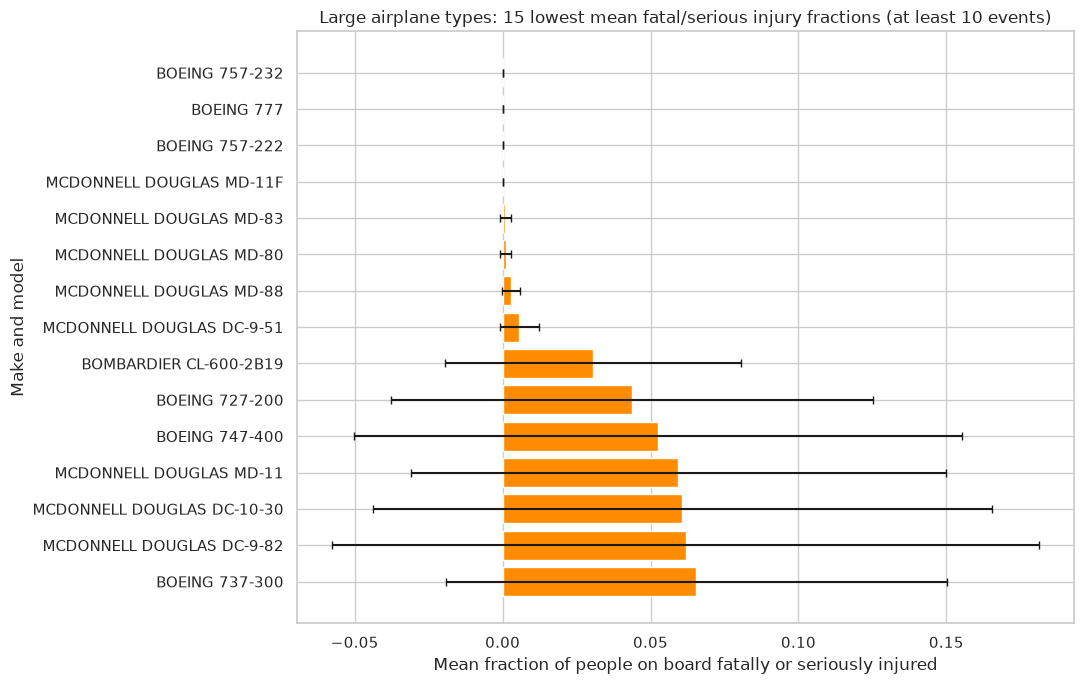

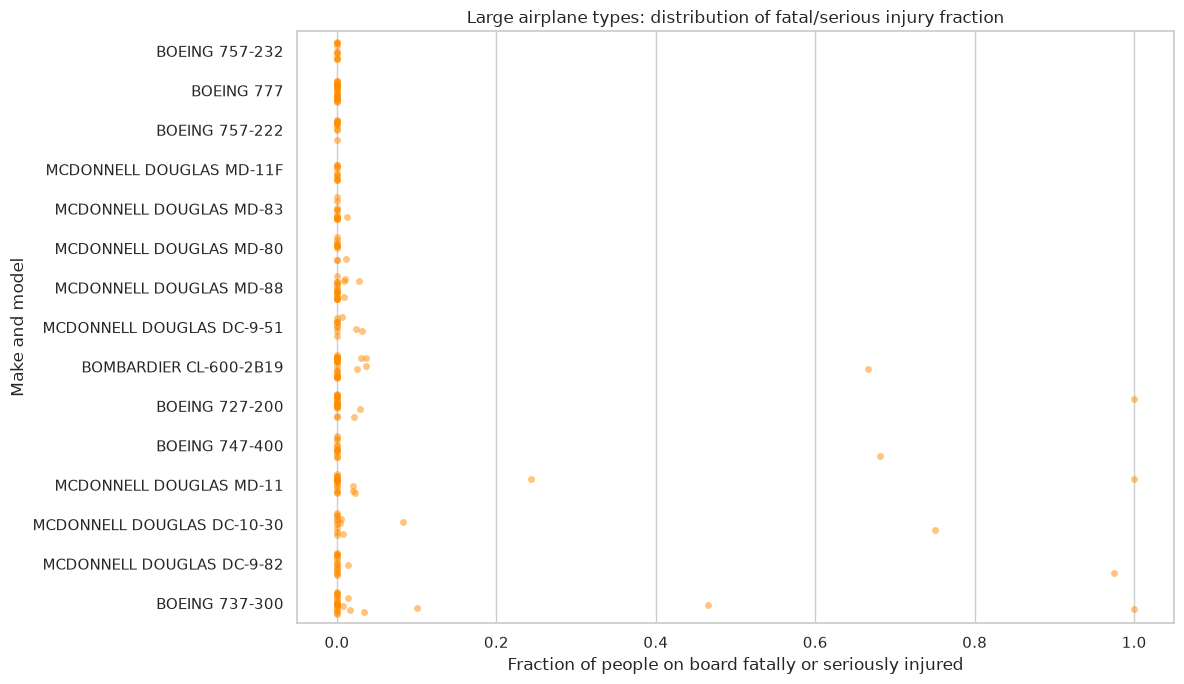

,n_events,mean_fatal_serious,destroyed_rate,ci95
Make.Model,,,,
BOEING 757-232,10,0.000,0.000,0.000
BOEING 777,24,0.000,0.042,0.000
BOEING 757-222,10,0.000,0.000,0.000
MCDONNELL DOUGLAS MD-11F,10,0.000,0.100,0.000
MCDONNELL DOUGLAS MD-83,13,0.001,0.077,0.002
MCDONNELL DOUGLAS MD-80,11,0.001,0.000,0.002
MCDONNELL DOUGLAS MD-88,20,0.003,0.000,0.003
MCDONNELL DOUGLAS DC-9-51,11,0.006,0.091,0.007
BOMBARDIER CL-600-2B19,26,0.031,0.038,0.050


In [9]:
def model_summary(data, min_events=10):
    g = data.groupby('Make.Model').agg(
        n_events=('Make.Model', 'size'),
        mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
        sem=('Fatal.Serious.Fraction', 'sem'),
        destroyed_rate=('Destroyed', 'mean'),
    )
    g['ci95'] = 1.96 * g['sem']
    return g[g['n_events'] >= min_events].drop(columns='sem')

large_models = model_summary(large, 10).sort_values('mean_fatal_serious')
print('Large plane types with at least 10 events:', len(large_models))

large_models_top = large_models.head(15)

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(large_models_top.index, large_models_top['mean_fatal_serious'], xerr=large_models_top['ci95'], color='darkorange', capsize=3)
ax.invert_yaxis()
ax.set_title('Large airplane types: 15 lowest mean fatal/serious injury fractions (at least 10 events)')
ax.set_xlabel('Mean fraction of people on board fatally or seriously injured')
ax.set_ylabel('Make and model')
plt.tight_layout()
plt.savefig('images/large_models_mean.png', dpi=130)
plt.show()

plt.figure(figsize=(12, 7))
sns.stripplot(data=large[large['Make.Model'].isin(large_models_top.index)], y='Make.Model', x='Fatal.Serious.Fraction',
              order=large_models_top.index, jitter=0.3, alpha=0.5, color='darkorange')
plt.title('Large airplane types: distribution of fatal/serious injury fraction')
plt.xlabel('Fraction of people on board fatally or seriously injured')
plt.ylabel('Make and model')
plt.tight_layout()
plt.savefig('images/large_models_strip.png', dpi=130)
plt.show()

display(large_models_top.round(3))

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small plane types (from the 10 lowest-risk makes) with at least 10 events: 41


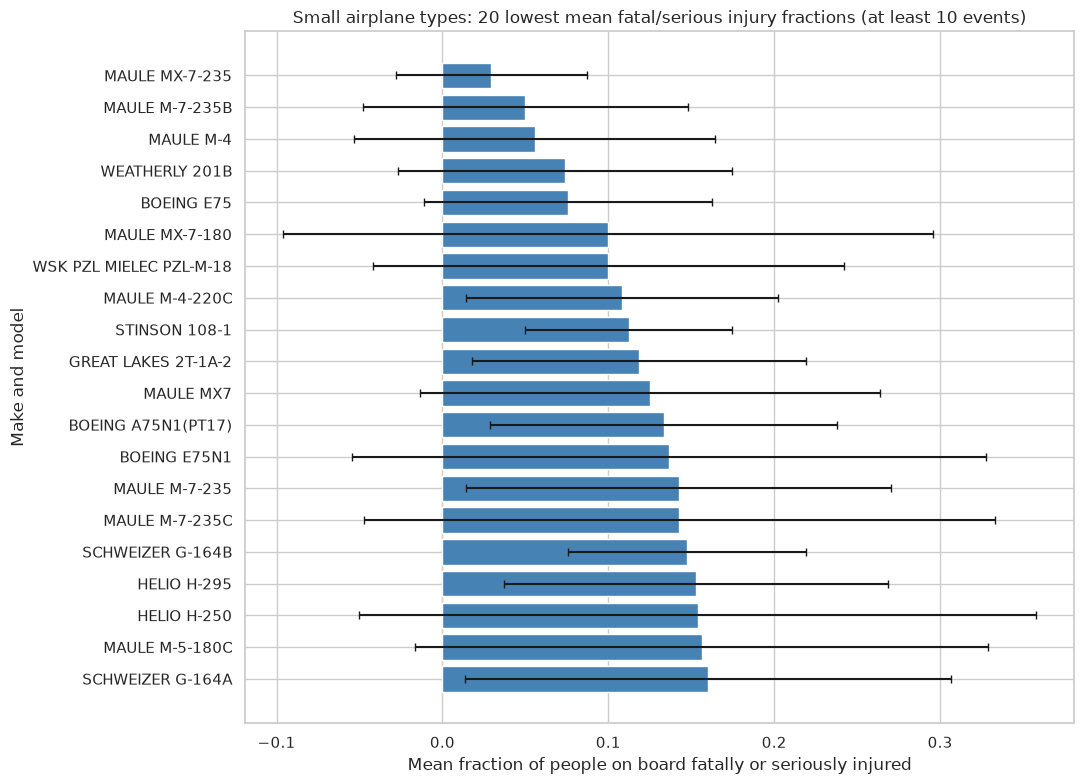

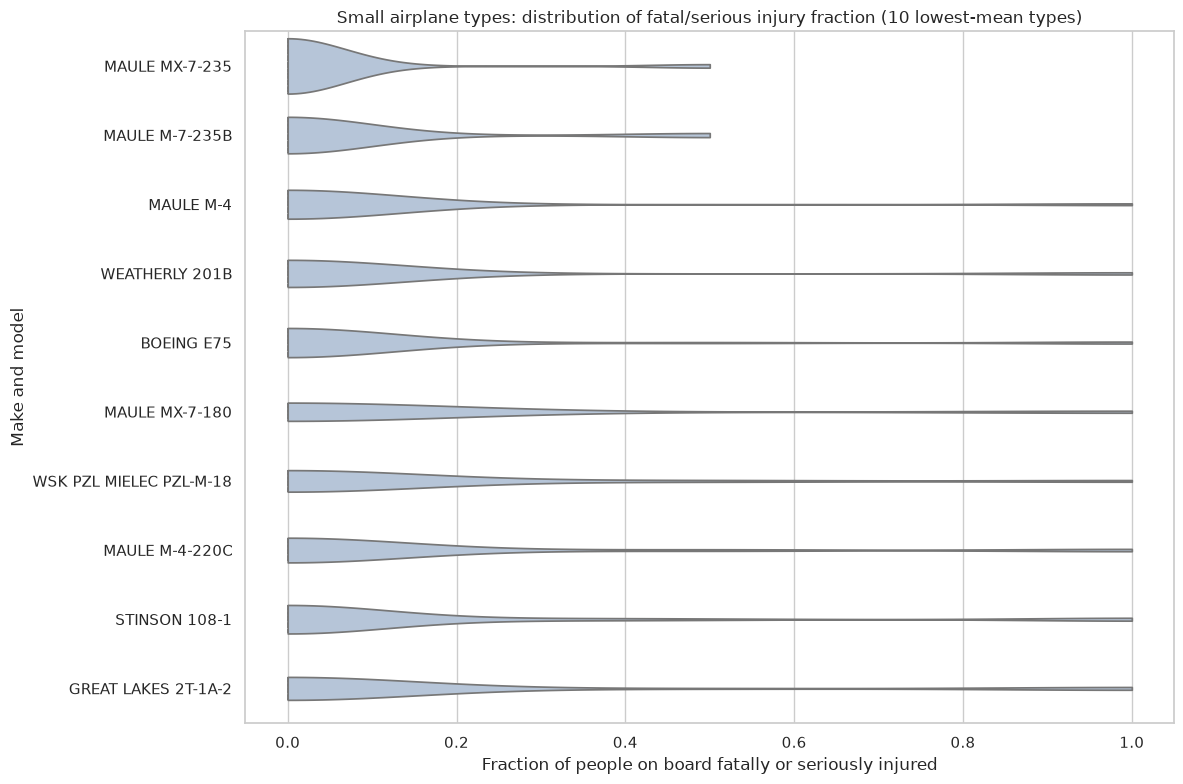

,n_events,mean_fatal_serious,destroyed_rate,ci95
Make.Model,,,,
MAULE MX-7-235,17,0.029,0.000,0.058
MAULE M-7-235B,10,0.050,0.000,0.098
MAULE M-4,18,0.056,0.056,0.109
WEATHERLY 201B,27,0.074,0.111,0.101
BOEING E75,33,0.076,0.121,0.087
MAULE MX-7-180,10,0.100,0.000,0.196
WSK PZL MIELEC PZL-M-18,15,0.100,0.200,0.142
MAULE M-4-220C,37,0.108,0.081,0.094
STINSON 108-1,83,0.112,0.145,0.062


In [10]:
small_models = model_summary(small[small['Make'].isin(small_top10)], 10).sort_values('mean_fatal_serious')
print('Small plane types (from the 10 lowest-risk makes) with at least 10 events:', len(small_models))

small_models_top = small_models.head(20)

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(small_models_top.index, small_models_top['mean_fatal_serious'], xerr=small_models_top['ci95'], color='steelblue', capsize=3)
ax.invert_yaxis()
ax.set_title('Small airplane types: 20 lowest mean fatal/serious injury fractions (at least 10 events)')
ax.set_xlabel('Mean fraction of people on board fatally or seriously injured')
ax.set_ylabel('Make and model')
plt.tight_layout()
plt.savefig('images/small_models_mean.png', dpi=130)
plt.show()

plt.figure(figsize=(12, 8))
sns.violinplot(data=small[small['Make.Model'].isin(small_models_top.index[:10])], y='Make.Model', x='Fatal.Serious.Fraction',
               order=small_models_top.index[:10], cut=0, inner='quartile', color='lightsteelblue')
plt.title('Small airplane types: distribution of fatal/serious injury fraction (10 lowest-mean types)')
plt.xlabel('Fraction of people on board fatally or seriously injured')
plt.ylabel('Make and model')
plt.tight_layout()
plt.savefig('images/small_models_violin.png', dpi=130)
plt.show()

display(small_models_top.round(3))

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Larger planes (at least 10 events per type).**
- Types with the lowest mean fatal/serious fraction: Boeing 757-232 and 757-222 (0.000, 10 events each), **Boeing 777 (0.000, 24 events, 4.2% destroyed)**, the MD-80 family (MD-80, MD-83, MD-88: all <= 0.003, 11 to 20 events), MD-11F (0.000, 10 events), DC-9-51 (0.006), **Bombardier CL-600-2B19 (0.031, 26 events, 3.8% destroyed)**, Boeing 727-200 (0.044, 24 events) and Boeing 747-400 (0.052, 13 events).
- The strip plot shows why: for these types almost every accident is a zero (no fatal or serious injuries), with only a handful of catastrophic events. With only 10 to 26 events per type, one additional crash would noticeably change the mean, and the intervals for types such as the 747-400 or DC-10-30 are wide (+/-0.10). The type-level results are best used as supporting evidence for the make-level recommendations (Boeing, McDonnell Douglas, Bombardier) rather than as precise rankings.

**Smaller planes (types from the 10 lowest-risk makes, at least 10 events).**
- The lowest means belong to the **Maule family** (MX-7-235: 0.029, M-7-235B: 0.050, M-4: 0.056, MX-7-180: 0.100, M-4-220C: 0.108 with 37 events), Weatherly 201B (0.074), Boeing-Stearman E75 (0.076), **Stinson 108-1 (0.112, 83 events)** and Great Lakes 2T-1A-2 (0.118).
- Almost all of these types have 95% intervals of +/-0.06 to +/-0.20 and many overlap, so individual types should not be ranked against each other with confidence. The consistent finding is the Maule *family*: many Maule types with low injury fractions and low destruction rates (several 0.00 to 0.08). Stinson 108-1 and Great Lakes 2T-1A-2 are the better-supported specific types due to larger sample sizes.
- The violin plot shows a large mass at 0 and a thin tail at 1 for each type, i.e. most accidents are survivable and the differences between types come from the size of the tail.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

The factors analyzed below are **Weather Condition**, **Phase of Flight** and **Number of Engines**. Events where the factor is `Unknown` are excluded from each comparison, and only categories with at least 100 events are compared.

#### Factor 1: Weather Condition

,n_events,mean_fatal_serious,destroyed_rate
Weather.Condition,,,
IMC,4725,0.669,0.586
VMC,52025,0.221,0.167


n_events  mean_fatal_serious  destroyed_rate
Size  Weather.Condition                                              
Large IMC                     217               0.228           0.230
      VMC                    1008               0.077           0.078
Small IMC                    4508               0.690           0.604
      VMC                   51017               0.224           0.169

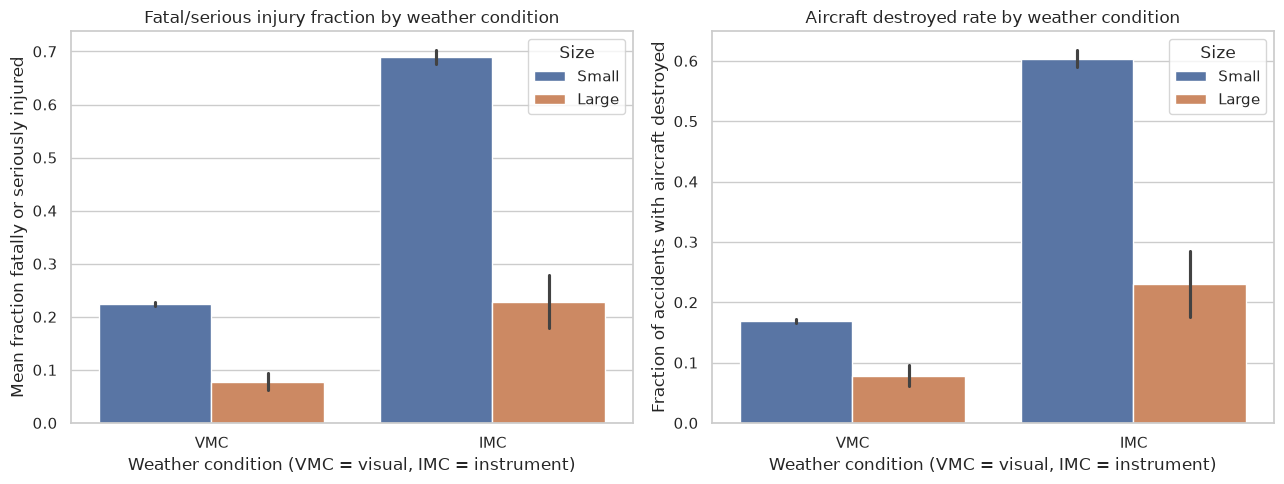

Mann-Whitney U on fatal/serious fraction (VMC vs IMC): p < 1e-300
Chi-square on destroyed vs weather: p < 1e-300


In [11]:
def factor_summary(data, col, min_events=100):
    g = data.groupby(col).agg(
        n_events=(col, 'size'),
        mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
        destroyed_rate=('Destroyed', 'mean'),
    )
    return g[g['n_events'] >= min_events]

weather = df[df['Weather.Condition'] != 'Unknown']
weather_summary = factor_summary(weather, 'Weather.Condition')
display(weather_summary.round(3))

weather_by_size = weather.groupby(['Size', 'Weather.Condition']).agg(
    n_events=('Make', 'size'),
    mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
    destroyed_rate=('Destroyed', 'mean'),
).round(3)
display(weather_by_size)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=weather, x='Weather.Condition', y='Fatal.Serious.Fraction', hue='Size', errorbar=('ci', 95), ax=axes[0])
axes[0].set_title('Fatal/serious injury fraction by weather condition')
axes[0].set_xlabel('Weather condition (VMC = visual, IMC = instrument)')
axes[0].set_ylabel('Mean fraction fatally or seriously injured')
sns.barplot(data=weather, x='Weather.Condition', y='Destroyed', hue='Size', errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Aircraft destroyed rate by weather condition')
axes[1].set_xlabel('Weather condition (VMC = visual, IMC = instrument)')
axes[1].set_ylabel('Fraction of accidents with aircraft destroyed')
plt.tight_layout()
plt.savefig('images/weather_condition.png', dpi=130)
plt.show()

# Statistical tests (VMC vs IMC)
vmc = weather[weather['Weather.Condition'] == 'VMC']
imc = weather[weather['Weather.Condition'] == 'IMC']
u, p_inj = stats.mannwhitneyu(vmc['Fatal.Serious.Fraction'], imc['Fatal.Serious.Fraction'])
chi2, p_dest, _, _ = stats.chi2_contingency(pd.crosstab(weather['Weather.Condition'], weather['Destroyed']))
fmt_p = lambda p: '< 1e-300' if p < 1e-300 else f'{p:.2e}'
print(f'Mann-Whitney U on fatal/serious fraction (VMC vs IMC): p {fmt_p(p_inj)}')
print(f'Chi-square on destroyed vs weather: p {fmt_p(p_dest)}')

**Weather condition strongly affects both injury and damage.**
- IMC (instrument meteorological conditions) accidents are far more severe: mean fatal/serious fraction **0.669 vs 0.221** in VMC and aircraft destroyed in **58.6% vs 16.7%** of accidents (4,725 IMC vs 52,025 VMC events).
- The pattern holds for both size groups: small planes 0.690 (IMC) vs 0.224 (VMC); large planes 0.228 vs 0.077 (217 IMC vs 1,008 VMC events). Confidence intervals in the bar plots do not overlap, and both a Mann-Whitney U test (injury fraction) and a chi-square test (destroyed) give p < 1e-300.
- Interpretation: accidents in low visibility are typically loss-of-control or controlled-flight-into-terrain events at speed, which are rarely survivable. Weather matters most for small aircraft, where the injury fraction triples in IMC. Caveat: we only observe accidents, not total flights, so this shows that IMC accidents are more severe, not that IMC flying has a given accident rate.

#### Factor 2: Phase of Flight

,n_events,mean_fatal_serious,destroyed_rate
Broad.phase.of.flight,,,
Maneuvering,4607,0.533,0.476
Climb,1420,0.420,0.425
Cruise,7082,0.352,0.344
Approach,4527,0.350,0.298
Descent,1249,0.340,0.326
Go-around,1161,0.300,0.288
Takeoff,8834,0.225,0.218
Standing,497,0.080,0.127
Landing,11858,0.034,0.042


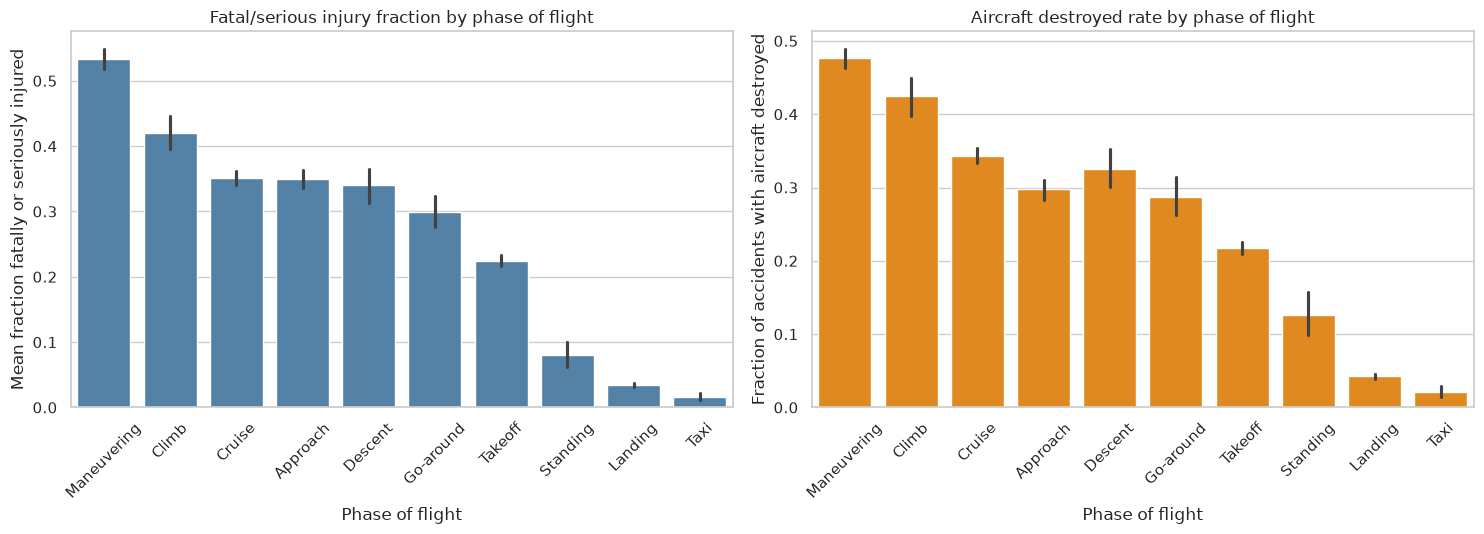

Kruskal-Wallis on fatal/serious fraction across phases: p < 1e-300
Chi-square on destroyed vs phase of flight: p < 1e-300


In [12]:
phase = df[df['Broad.phase.of.flight'] != 'Unknown']
phase_summary = factor_summary(phase, 'Broad.phase.of.flight').sort_values('mean_fatal_serious', ascending=False)
display(phase_summary.round(3))

order = phase_summary.index
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=phase[phase['Broad.phase.of.flight'].isin(order)], x='Broad.phase.of.flight', y='Fatal.Serious.Fraction',
            order=order, errorbar=('ci', 95), color='steelblue', ax=axes[0])
axes[0].set_title('Fatal/serious injury fraction by phase of flight')
axes[0].set_xlabel('Phase of flight')
axes[0].set_ylabel('Mean fraction fatally or seriously injured')
sns.barplot(data=phase[phase['Broad.phase.of.flight'].isin(order)], x='Broad.phase.of.flight', y='Destroyed',
            order=order, errorbar=('ci', 95), color='darkorange', ax=axes[1])
axes[1].set_title('Aircraft destroyed rate by phase of flight')
axes[1].set_xlabel('Phase of flight')
axes[1].set_ylabel('Fraction of accidents with aircraft destroyed')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('images/phase_of_flight.png', dpi=130)
plt.show()

groups = [g['Fatal.Serious.Fraction'].values for _, g in phase[phase['Broad.phase.of.flight'].isin(order)].groupby('Broad.phase.of.flight')]
h, p_kw = stats.kruskal(*groups)
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(phase[phase['Broad.phase.of.flight'].isin(order)]['Broad.phase.of.flight'],
                                                       phase[phase['Broad.phase.of.flight'].isin(order)]['Destroyed']))
fmt_p = lambda p: '< 1e-300' if p < 1e-300 else f'{p:.2e}'
print(f'Kruskal-Wallis on fatal/serious fraction across phases: p {fmt_p(p_kw)}')
print(f'Chi-square on destroyed vs phase of flight: p {fmt_p(p_chi)}')

**Phase of flight is strongly related to severity.**
- The most severe phases are **maneuvering (0.533 fatal/serious, 47.6% destroyed)**, **climb (0.420, 42.5%)**, **cruise (0.352, 34.4%)**, approach (0.350, 29.8%) and descent (0.340, 32.6%).
- The least severe are **landing (0.034, 4.2% destroyed)** and **taxi (0.016, 2.2%)**, followed by standing (0.080) and takeoff (0.225).
- Landing is the most common accident phase (11,858 events), but the vast majority are low-speed events with no serious injuries. The deadliest phases occur at altitude or at low altitude under high energy (maneuvering, climb), where there is little room to recover. Differences across phases are statistically significant (Kruskal-Wallis and chi-square p < 1e-300) and the error bars are narrow because every plotted phase has at least 497 events.
- Implication for the client: the number of landing/taxi incidents drives claim *frequency*, while maneuvering, climb and cruise events drive claim *severity* (total loss and fatalities).

#### Factor 3 (additional): Number of Engines

,n_events,mean_fatal_serious,destroyed_rate
Number.of.Engines,,,
1.0,48414,0.251,0.188
2.0,7914,0.325,0.295
3.0,239,0.043,0.054
4.0,250,0.174,0.188


n_events  mean_fatal_serious  destroyed_rate
Size  Number.of.Engines                                              
Large 2.0                     937               0.097           0.098
      3.0                     215               0.041           0.047
      4.0                     119               0.110           0.101
Small 1.0                   48414               0.251           0.188
      2.0                    6977               0.356           0.321
      3.0                      24               0.062           0.125
      4.0                     131               0.232           0.267

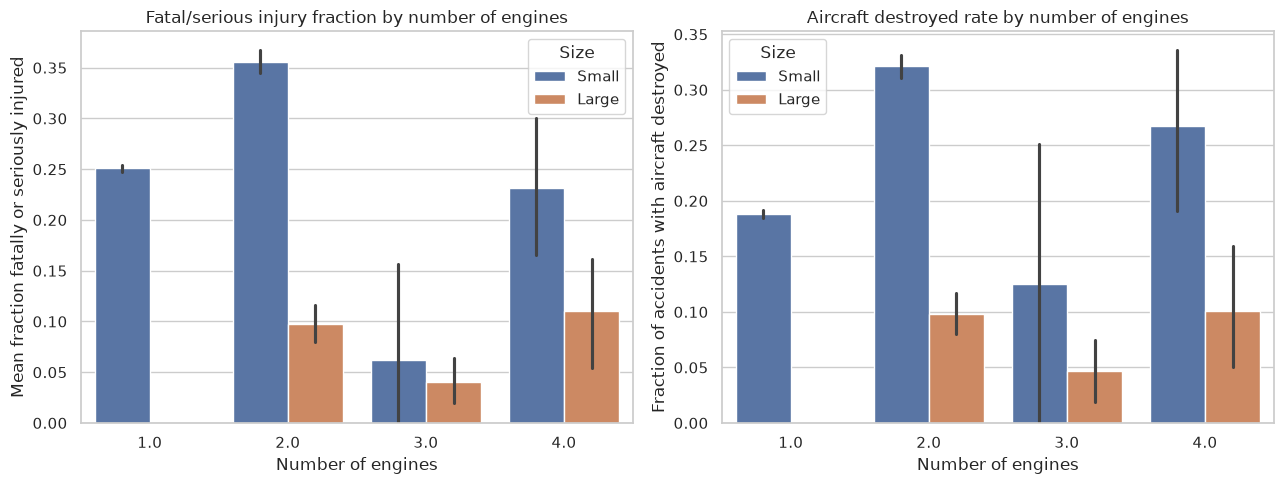

In [13]:
engines = df[df['Number.of.Engines'].isin([1, 2, 3, 4])]
engine_summary = factor_summary(engines, 'Number.of.Engines')
display(engine_summary.round(3))

engines_by_size = engines.groupby(['Size', 'Number.of.Engines']).agg(
    n_events=('Make', 'size'),
    mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
    destroyed_rate=('Destroyed', 'mean')).round(3)
display(engines_by_size)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=engines, x='Number.of.Engines', y='Fatal.Serious.Fraction', hue='Size', errorbar=('ci', 95), ax=axes[0])
axes[0].set_title('Fatal/serious injury fraction by number of engines')
axes[0].set_xlabel('Number of engines')
axes[0].set_ylabel('Mean fraction fatally or seriously injured')
sns.barplot(data=engines, x='Number.of.Engines', y='Destroyed', hue='Size', errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Aircraft destroyed rate by number of engines')
axes[1].set_xlabel('Number of engines')
axes[1].set_ylabel('Fraction of accidents with aircraft destroyed')
plt.tight_layout()
plt.savefig('images/number_of_engines.png', dpi=130)
plt.show()

**Number of engines.**
- Single-engine events: 0.251 fatal/serious fraction, 18.8% destroyed (48,414 events). Twin-engine events: **0.325 and 29.5% destroyed** (7,914 events). The difference is clear within small planes (twins 0.356 vs singles 0.251; 0.321 vs 0.188 destroyed).
- This is a counter-intuitive result: twin-engine piston aircraft are not safer in accidents. A likely explanation is that light twins are faster, more complex, carry more people and are flown more often in instrument conditions, so when an accident does happen it is more severe. The engine count is therefore confounded with aircraft type and mission, and should not be read as a causal effect.
- Three- and four-engine aircraft show low values (0.043 for three engines, 0.174 for four) but these are mainly large airliners (727, DC-10, MD-11, 747) and only 24 small three-engine events exist, so these comparisons are weaker (239 and 250 events).

## Final Recommendations

### Recommendations for the client

**Small aircraft (fewer than 20 people on board)**
1. **Maule** (many models, especially the M-4 / M-7 / MX-7 family): the most reliable recommendation, with 569 events, a low fatal/serious fraction (0.153) and a low destroyed rate (0.093).
2. **Aviat** (destroyed rate 0.039 / 0.086) and **Diamond** (destroyed rate 0.073): lowest destruction rates, although their injury fractions are only average.
3. Worth considering with lower confidence (smaller samples, wide intervals): **Waco, Helio, Great Lakes, Stinson (108-1)**.
4. Higher-risk makes in this dataset: Beech (0.371), Mooney (0.362) and Cirrus (0.440) for injury fraction, and Grumman and Schweizer for destruction (0.241 and 0.225).

**Larger passenger aircraft (20 or more people on board)**
1. **Boeing** (best-supported: 852 events; 0.105 injury fraction, 0.112 destroyed). Strongest types: 777, 757-222 / 757-232, 727-200, 747-400.
2. **McDonnell Douglas** (0.051 injury fraction, 181 events): MD-80 / MD-83 / MD-88, MD-11F and DC-9-51.
3. **Bombardier** (CL-600-2B19: 0.031 injury fraction and the lowest destroyed rate of any large make, 0.069) and **Embraer** (0.111, 0.103 destroyed).
4. Treat Airbus as a mid-range option, and be cautious about older Douglas, De Havilland and Beech 1900 commuter types, which have the highest fatal/serious fractions and destruction rates.

**Operating conditions that drive severity**
- Accidents in **IMC conditions** have about three times the fatal/serious injury fraction and 3.5 times the destroyed rate of VMC accidents.
- **Maneuvering, climb and cruise** accidents are the most severe, while landing and taxi accidents are frequent but rarely serious.

### Limitations
- The data only contains accidents and incidents, with no exposure information (flights or flight hours), so the analysis measures how severe an accident is, not how likely an accident is.
- Many type-level samples are small (10 to 40 events). Confidence intervals overlap, so rankings between neighbouring makes/models should not be over-interpreted.
- Airplane size was estimated from the 95th percentile of people on board in recorded accidents, and some models with very few events may be misclassified.
- The injury fraction depends on the occupancy estimate (sum of the four injury columns, with missing counts assumed to be 0).
- Make/model names were normalized for the most common variants, but not every spelling variant was merged.